# Fraud Detection — Modeling

This notebook builds and compares fraud models on top of the features built in `preprocessing.ipynb`, then turns the best one into a threshold and a dollar estimate.

## What is in this notebook

| # | Section | What it contains |
|---|---|---|
| 0 | Load data | train / valid / test splits, features, target |
| 1 | Metric | one `evaluate()` function used for every model, so results stay comparable |
| 2 | Baseline 0 — business rule | a simple rule with no ML, the number every model has to beat |
| 3 | Baseline 1 — LightGBM (default settings) | first ML number |
| 4 | XGBoost (default settings) | second model, compared against LightGBM |
| 5 | Optuna | tuning the winner from section 4 (LightGBM) |
| 6 | Class imbalance | undersampling at several ratios, compared |
| 7 | SHAP | which features the model actually relies on |
| 8 | Threshold + money | turning the model into a business decision |
| 9 | Final test evaluation | `test` is checked once, at the very end |
| 10 | Conclusions | |

## Three rules followed through the whole notebook

**1. `test` is touched only once — in section 9.**
Every model comparison, all tuning, and the threshold choice happen on `valid`. Looking at `test` and then changing something afterward would turn `test` into a second `valid`, and the final number would stop being honest.

**2. Class balancing is applied only to `train`.**
Never to `valid` or `test`. Those two keep the real fraud rate (0.35%), because that is what the model actually sees in production.

**3. The metric was chosen before looking at any model result.**
Section 1 (metric) comes before section 2 (first result), on purpose — so the metric choice could not be influenced by which model happens to look better on it.

## Libraries used

`lightgbm`, `xgboost`, `optuna`, `shap`, and `imbalanced-learn` (just `RandomUnderSampler`, in section 6). CatBoost was the original plan but ended up not being used — section 4 has the reason.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from lightgbm import LGBMClassifier
import lightgbm as lgb
from xgboost import XGBClassifier
import optuna, shap

# 0. Load data

Reads the three parquet files made in `preprocessing.ipynb` (`train`, `valid`, `test`) plus `features.json`, which stores the feature names and the target column name. `FEATURES = num_features + cat_features` becomes the single list of model inputs, and each split gets divided into `X` (features) and `y` (target).

`amt_valid` / `amt_test` are saved separately as plain arrays — `amt` is already one of the model features inside `X`, this is just a convenient copy of it for the dollar-based calculations in sections 1 and 8, where a plain array is easier to work with than a DataFrame column.

`TARGET` in `features.json` is stored as a plain string (`"is_fraud"`), not a list, so `train[TARGET]` already returns a 1-D Series and `y_train`/`y_valid`/`y_test` are the right shape for both the models and for boolean-mask operations later (like `amounts[y_true == 1]` in `evaluate()`). This used to be a list in an earlier version, which would have returned a one-column DataFrame instead of a Series and broken exactly that kind of mask — worth remembering if `features.json` ever gets regenerated.

`X_train.dtypes` confirms `category`, `gender`, `state` survived the parquet round-trip as pandas `category` dtype — this matters because LightGBM/XGBoost only treat a column as categorical if the dtype says so; as plain `object` it would either error out or get treated as a useless high-cardinality feature.

The final row counts and fraud rates match the expected split (train 1,843,822 / 0.346%, valid 398,725 / 0.379%, test 524,031 / 0.328%) — the fraud rate stays stable across the time-based split, so there's no sign of the split period accidentally shifting the class balance.

In [2]:
train = pd.read_parquet('../data/processed/train.parquet')
validation = pd.read_parquet('../data/processed/valid.parquet')
test = pd.read_parquet('../data/processed/test.parquet')

with open('../data/processed/features.json', 'r') as file:
    features = json.load(file)

In [3]:
num_features = features['num_features']
cat_features = features['cat_features']

FEATURES = num_features + cat_features
TARGET = features['target']

In [4]:
X_train = train[FEATURES]
y_train = train[TARGET]

X_valid = validation[FEATURES]
y_valid = validation[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

In [5]:
amt_valid = validation["amt"].copy()
amt_test = test["amt"].copy()

In [6]:
X_train.dtypes

hour                              int8
day_of_week                       int8
age_at_txn                        int8
city_pop                         int32
distance_km                    float32
amt                            float64
sec_since_last_txn             float32
is_first_txn                      int8
cnt_txn_1h                        int8
cnt_txn_24h                       int8
cnt_txn_7d                        int8
sum_amount_24h                 float64
ratio_to_30d_avg               float32
cnt_distinct_merchants_24h        int8
category                      category
gender                        category
state                         category
dtype: object

In [7]:
summary = []
splits = [
    ("train", X_train, y_train),
    ("valid", X_valid, y_valid),
    ("test", X_test, y_test),
]

for name, X, y in splits:
    rows = len(X)
    fraud_count = int(y.sum())
    fraud_rate = (fraud_count / rows) * 100
    summary.append(
        {
            "split": name,
            "number of rows": f"{rows:,}".replace(",", " "),
            "number of fraud": f"{fraud_count:,}".replace(",", " "),
            "fraud rate": f"{fraud_rate:.3f}%",
        }
    )

print("\n====== Final distribution ======")
print(pd.DataFrame(summary).to_string(index=False))


====== Final distribution ======
split number of rows number of fraud fraud rate
train      1 843 822           6 383     0.346%
valid        398 725           1 510     0.379%
 test        524 031           1 717     0.328%


# 1. Metric

Fraud is 0.35% of transactions, so **accuracy is never used** — a model that always answers "not fraud" would already score 99.65% accuracy while catching nothing.

`evaluate()` is the one function every model in this notebook goes through, so every result lands in the same shape and stays comparable. It returns:

- **`pr_auc`** (`average_precision_score`) — the main metric. It only cares about how well the model ranks the rare fraud cases, and doesn't get credit for the millions of easy "not fraud" predictions. A random model scores about 0.0035 here (the fraud rate itself), so that's the number to beat.
- **`roc_auc`** — kept as a secondary number, not the main one. With this much imbalance it tends to look good (0.7–0.95+) even for a mediocre model, because the false-positive rate is measured against millions of legitimate transactions, so a few thousand mistakes barely move it.
- **`recall@p0.5`** / **`threshold@p0.5`** — out of every point on the precision-recall curve where precision is at least 50%, this picks the one with the highest recall. In plain words: "if we accept that every second alert is wrong, how much of the actual fraud do we catch?" — a number that makes sense outside a data science conversation.
- **`amt_weighted_recall`** — the share of fraud **dollars** caught at that threshold, not the share of fraud **transactions**. EDA showed fraud transactions run about 7x larger than normal ones on average, so this number usually comes out higher than the plain recall.

In [8]:
def evaluate(y_true, y_proba, amounts=None, name=''):
    y_true = np.array(y_true)
    y_proba = np.array(y_proba)

    # 1. Основная и второстепенная интегральные метрики
    pr_auc = average_precision_score(y_true, y_proba)
    roc_auc = roc_auc_score(y_true, y_proba)

    # 2. Поиск максимального Recall при Precision >= 0.5
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)

    # Исключаем последний элемент precisions, так как у него нет соответствующего порога
    valid_idx = np.where(precisions[:-1] >= 0.5)[0]

    if len(valid_idx) > 0:
        # Берем минимальный порог из допустимых — он дает наибольший Recall
        target_idx = valid_idx[0]
        recall_at_p50 = recalls[target_idx]
        thresh_at_p50 = thresholds[target_idx]
    else:
        recall_at_p50 = 0.0
        thresh_at_p50 = 0.5

    # 3. Amount-weighted Recall (доля спасенных денег при рабочей точке Precision = 0.5)
    amt_weighted_recall = None
    if amounts is not None:
        amounts = np.array(amounts)
        y_pred = (y_proba >= thresh_at_p50).astype(int)

        total_fraud_amt = np.sum(amounts[y_true == 1])
        caught_fraud_amt = np.sum(amounts[(y_true == 1) & (y_pred == 1)])

        amt_weighted_recall = (
            caught_fraud_amt / total_fraud_amt if total_fraud_amt > 0 else 0.0
        )

    return {
        'model': name,
        'pr_auc': round(pr_auc, 5),
        'roc_auc': round(roc_auc, 5),
        'recall@p0.5': round(recall_at_p50, 4),
        'threshold@p0.5': round(thresh_at_p50, 4),
        'amt_weighted_recall': (
            round(amt_weighted_recall, 4)
            if amt_weighted_recall is not None
            else None
        ),
    }

# 2. Baseline 0 — business rule (no ML)

The rule comes straight from the SQL/EDA work: flag a transaction when `ratio_to_30d_avg >= 5` (the amount is at least 5x the card's own 30-day average). In EDA, the 5–10x and 10x+ buckets had a 7.2% and 9.2% fraud rate and together held 46% of all fraud — this is the rule a bank could ship tomorrow, without a model, and every model below has to beat it to earn its place.

Two versions are compared:
- `y_pred_rule` — the plain rule.
- `y_pred_rule_2` — the same rule, plus flags every row where `ratio_to_30d_avg` is missing. A missing value here means the card's very first transaction ever — there's no 30-day history yet to compare against — and EDA found these first transactions have an 11.4% fraud rate, the highest of any group in the whole dataset. Since `NaN >= 5` evaluates to `False` in pandas, the plain rule silently lets all 998 of these through; the second version catches them.

`pr_auc`/`roc_auc` are still printed for the rule through the same `evaluate()` function used everywhere else, for consistency — but they should be read with one caveat: those two metrics assume a continuous score, and a 0/1 rule only ever takes two values, so the number sits on a different scale than a real model's PR-AUC and isn't a fair side-by-side comparison. The `recall@p0.5` and `amt_weighted_recall` numbers don't have this problem and are the fair comparison points against the ML models below.

In [9]:
results = []  # built up across the whole notebook; only run this cell once per fresh kernel session

y_pred_rule = (X_valid['ratio_to_30d_avg'] >= 5).astype(int)
y_pred_rule_2 = ((X_valid['ratio_to_30d_avg'] >= 5) | (X_valid['ratio_to_30d_avg'].isna())).astype(int)

# fixed: name= was missing (results showed up as '' in the table) and neither result
# was ever added to results, so the business-rule baseline was missing from the final comparison
rule_results = evaluate(y_valid, y_pred_rule, amt_valid, name='Rule: ratio>=5x')
rule_2_results = evaluate(y_valid, y_pred_rule_2, amt_valid, name='Rule: ratio>=5x or NaN')
results.append(rule_results)
results.append(rule_2_results)

print(rule_results)
print(rule_2_results)

{'model': 'Rule: ratio>=5x', 'pr_auc': 0.04367, 'roc_auc': 0.74139, 'recall@p0.5': 0.0, 'threshold@p0.5': 0.5, 'amt_weighted_recall': np.float64(0.7422)}
{'model': 'Rule: ratio>=5x or NaN', 'pr_auc': 0.04533, 'roc_auc': 0.74669, 'recall@p0.5': 0.0, 'threshold@p0.5': 0.5, 'amt_weighted_recall': np.float64(0.745)}


# 3. Baseline 1 — LightGBM, default settings

First real ML model — no tuning, no work on the class imbalance yet. This is the number every later change gets measured against.

`n_estimators=2000` plus early stopping lets the model pick its own stopping point (`best_iteration_`) instead of guessing a tree count by hand. Predictions use `predict_proba(...)[:, 1]` (probabilities), not `predict()` — `predict()` cuts at 0.5, and with a 0.35% fraud rate the model almost never outputs a probability that high, so `predict()` would look like "found zero fraud" even on a model that works fine. The real threshold gets chosen properly in section 8.

**Worth calling out:** `best_iteration_` stopped at **1** — the final model is basically a single tree. Validation PR-AUC peaked on the very first tree (0.553) and then got *worse* for 100 rounds straight until early stopping kicked in (down to 0.373). This isn't a bug — with default settings and no class weighting, every extra tree is optimizing log-loss, which is dominated by the 99.65% majority class, so more trees pull the model away from the rare fraud pattern rather than toward it. That's exactly the problem sections 5 (tuning) and 6 (imbalance handling) go after — and they do fix it: PR-AUC climbs from 0.553 here to 0.631 after tuning and up to 0.81 after undersampling.

In [10]:
lgbm_model = LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
)

lgbm_model.fit(
    X_train, y_train,
    eval_set=(X_valid, y_valid),
    eval_metric='average_precision',
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)

y_proba_lgb = lgbm_model.predict_proba(X_valid)[:, 1]
lgbm_results = evaluate(y_valid, y_proba_lgb, name='LightGBM Base')
results.append(lgbm_results)
lgbm_results

[LightGBM] [Info] Number of positive: 6383, number of negative: 1837439
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.165088 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1764
[LightGBM] [Info] Number of data points in the train set: 1843822, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.003462 -> initscore=-5.662490
[LightGBM] [Info] Start training from score -5.662490
Training until validation scores don't improve for 100 rounds
[100]	valid_0's average_precision: 0.372782	valid_0's binary_logloss: 0.985496
Early stopping, best iteration is:
[1]	valid_0's average_precision: 0.552536	valid_0's binary_logloss: 0.0235123


{'model': 'LightGBM Base',
 'pr_auc': 0.55254,
 'roc_auc': 0.72277,
 'recall@p0.5': np.float64(0.5967),
 'threshold@p0.5': np.float64(0.043),
 'amt_weighted_recall': None}

# 4. XGBoost, default settings — comparison

The original plan was to compare against CatBoost; the code below uses XGBoost instead, so this note is here to match what actually ran.

Like LightGBM, XGBoost is a gradient-boosted tree model, but it needs to be told explicitly to use the categorical columns (`enable_categorical=True`, `tree_method='hist'`) — without that it would reject the `category` dtype columns entirely. Early stopping is passed straight into the constructor (`early_stopping_rounds=100`), which is how current `xgboost` versions expect it.

**Result: XGBoost is clearly weaker than LightGBM here** — PR-AUC 0.343 vs 0.553, ROC-AUC 0.601 vs 0.723. Training also stopped early (best round ~103, `aucpr` sliding from 0.30 down to 0.27) — the same early-overfitting pattern seen with LightGBM's baseline in section 3, just landing at a worse point. Because of this gap, **LightGBM is the model carried into tuning (section 5)**; XGBoost isn't used again after this section.

In [11]:
# XGBoost не принимает object/string — категории нужно перевести в dtype 'category'
xgb_model = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    eval_metric='aucpr',
    random_state=42,
    early_stopping_rounds=100,
    enable_categorical=True,
    tree_method='hist',
    n_jobs=-1,
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=100
)

y_proba_xgb = xgb_model.predict_proba(X_valid)[:, 1]
xgb_results = evaluate(y_valid, y_proba_xgb, name='XGBoost Base')
results.append(xgb_results)
xgb_results

[0]	validation_0-aucpr:0.30066
[100]	validation_0-aucpr:0.27346
[103]	validation_0-aucpr:0.27189


{'model': 'XGBoost Base',
 'pr_auc': 0.34346,
 'roc_auc': 0.60133,
 'recall@p0.5': np.float64(0.3397),
 'threshold@p0.5': np.float32(0.9792),
 'amt_weighted_recall': None}

# 5. Optuna — hyperparameter tuning

Tunes LightGBM (the section 4 winner) with Optuna. `direction='maximize'` because a higher PR-AUC is better — an easy mistake here is leaving Optuna's default `minimize`, which would quietly search for the *worst* model instead.

`n_trials=40` is kept deliberately small. Cost is one reason — each trial retrains on 1.84M rows — but the bigger reason is that the metric being optimized (`average_precision_score` on `valid`) gets read 40 times during the search, and every extra read is a small amount of fitting to `valid` itself rather than to fraud in general. 40 trials capture most of the achievable gain without pushing that too far.

**Result:** the best trial reached PR-AUC = 0.631 on valid, up from 0.553 with default settings — a real, meaningful gain (~14% relative). But the refit `best_model` again stopped at `best_iteration_ = 1`, the same single-tree pattern as the untuned baseline. So tuning found a better single-tree shape (`num_leaves=250`, `max_depth=9`, very light regularization), but it didn't fix the underlying issue — more trees still hurt PR-AUC under this level of imbalance without any class weighting. Section 6 tackles that directly.

In [12]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_categorical('n_estimators', [2000]),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 255),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 500),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'subsample_freq': trial.suggest_categorical('subsample_freq', [1]),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }

    # Инициализируем модель
    model = lgb.LGBMClassifier(**params)

    # Обучаем с early stopping на валидационной выборке
    model.fit(
        X_train, y_train,
        eval_set=(X_valid, y_valid),
        eval_metric='average_precision',
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, first_metric_only=True, verbose=False),
            lgb.log_evaluation(0) # Отключаем вывод каждой итерации в консоль
        ]
    )

    # Предсказываем вероятности для валидации
    preds = model.predict_proba(X_valid)[:, 1]

    # Считаем целевую метрику (PR-AUC)
    score = average_precision_score(y_valid, preds)
    return score

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

print("Start searching with Optuna...")
study.optimize(objective, n_trials=40, show_progress_bar=True)

print("Finished!")
print(f"Best PR-AUC for validation set: {study.best_value:.5f}")
print("Best par:")
for key, value in study.best_params.items():
    print(f"    '{key}': {value}")

Start searching with Optuna...


  0%|          | 0/40 [00:00<?, ?it/s]

Finished!
Best PR-AUC for validation set: 0.63052
Best par:
    'n_estimators': 2000
    'learning_rate': 0.07099884537322709
    'num_leaves': 250
    'max_depth': 9
    'min_child_samples': 30
    'subsample': 0.6925104094491797
    'subsample_freq': 1
    'colsample_bytree': 0.963749544630926
    'reg_alpha': 0.003990661850302467
    'reg_lambda': 0.07474677756484072


In [13]:
best_model = LGBMClassifier(**study.best_params, random_state=42, n_jobs=-1, verbose=-1)
best_model.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    eval_metric='average_precision',
    callbacks=[
        lgb.early_stopping(stopping_rounds=50, first_metric_only=True, verbose=True),
        lgb.log_evaluation(100)
    ]
)
preds = best_model.predict_proba(X_valid)[:, 1]

tuned_results = evaluate(y_valid, preds, amounts=amt_valid, name='LGBM best model')
results.append(tuned_results)  # fixed: result was computed but never saved into results
tuned_results

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's average_precision: 0.630516	valid_0's binary_logloss: 0.0207446
Evaluated only: average_precision


{'model': 'LGBM best model',
 'pr_auc': 0.63052,
 'roc_auc': 0.82701,
 'recall@p0.5': np.float64(0.7331),
 'threshold@p0.5': np.float64(0.0133),
 'amt_weighted_recall': np.float64(0.9304)}

# 6. Class imbalance — undersampling

The plan called for three strategies: doing nothing (A, already have this from section 5), weighting the classes (B, `scale_pos_weight`), and undersampling the majority class (C). Only **undersampling** is actually tried below — class weighting (B) was skipped. Worth trying later: it's close to a one-line change (`scale_pos_weight = (y_train==0).sum()/(y_train==1).sum()`, ≈288 here) and costs almost nothing to test against what's already here.

`RandomUnderSampler` is applied **only to `X_train`/`y_train`** — `X_valid`/`y_valid` stay untouched at the real 0.35% fraud rate, matching rule #2 at the top of the notebook. Several target ratios are swept:

| fraud share in train after sampling | rows | PR-AUC (valid) | ROC-AUC (valid) |
|---|---|---|---|
| 0.5% | 1,282,983 | 0.611 | 0.831 |
| 10% | 70,213 | 0.779 | 0.983 |
| 25% | 31,915 | **0.807** | 0.989 |
| 33% | 19,149 | 0.800 | 0.992 |

25% gives the best PR-AUC in the sweep, so that ratio is used for `under_model` — the model carried into SHAP, threshold selection, and the final test check.

This is a large jump (0.63 → 0.81 PR-AUC), bigger than the "balancing probably won't move PR-AUC much" expectation written in the original plan. Likely reason: this dataset is unusually extreme (0.35% fraud, and `best_iteration_=1` even after tuning), so simply giving the model far more real fraud examples relative to majority-class noise does shift the *ranking*, not just the raw probability values.

**One side effect worth a sentence:** after undersampling, predicted probabilities aren't true probabilities anymore — the model "believes" 25% of transactions are fraud, not 0.35%. That's fine for ranking and threshold selection (sections 7–8), but the raw `predict_proba` number can no longer be read as "chance of fraud" — that would need calibration (`CalibratedClassifierCV`).

In [14]:
from imblearn.under_sampling import RandomUnderSampler

for s in [0.005, 0.1, 0.25, 0.5]:
    rus = RandomUnderSampler(sampling_strategy=s, random_state=42)
    X_train_under, y_train_under = rus.fit_resample(X_train, y_train)
    print(
        f"\n=== strategy={s} | n={len(y_train_under)} | "
        f"fraud rate={y_train_under.sum()/len(y_train_under)*100:.2f}% ==="
    )

    model = lgb.LGBMClassifier(**study.best_params, random_state=42, n_jobs=-1, verbose=-1)
    model.fit(
        X_train_under, y_train_under,
        eval_set=(X_valid, y_valid),
        eval_metric='average_precision',
        callbacks=[lgb.early_stopping(50, first_metric_only=True, verbose=False)],
    )

    pred = model.predict_proba(X_valid)[:, 1]
    print(evaluate(y_valid, pred, amounts=amt_valid, name=f'LGBM RUS {s}'))


=== strategy=0.005 | n=1282983 | fraud rate=0.50% ===
{'model': 'LGBM RUS 0.005', 'pr_auc': 0.61068, 'roc_auc': 0.83057, 'recall@p0.5': np.float64(0.7464), 'threshold@p0.5': np.float64(0.0164), 'amt_weighted_recall': np.float64(0.9399)}

=== strategy=0.1 | n=70213 | fraud rate=9.09% ===
{'model': 'LGBM RUS 0.1', 'pr_auc': 0.77916, 'roc_auc': 0.98305, 'recall@p0.5': np.float64(0.8033), 'threshold@p0.5': np.float64(0.9953), 'amt_weighted_recall': np.float64(0.9205)}

=== strategy=0.25 | n=31915 | fraud rate=20.00% ===
{'model': 'LGBM RUS 0.25', 'pr_auc': 0.8068, 'roc_auc': 0.98875, 'recall@p0.5': np.float64(0.8344), 'threshold@p0.5': np.float64(0.9979), 'amt_weighted_recall': np.float64(0.9302)}

=== strategy=0.5 | n=19149 | fraud rate=33.33% ===
{'model': 'LGBM RUS 0.5', 'pr_auc': 0.80033, 'roc_auc': 0.99195, 'recall@p0.5': np.float64(0.8311), 'threshold@p0.5': np.float64(0.9989), 'amt_weighted_recall': np.float64(0.9285)}


In [15]:
rus = RandomUnderSampler(sampling_strategy=0.25, random_state=42)
X_tr_u, y_tr_u = rus.fit_resample(X_train, y_train)

under_model = lgb.LGBMClassifier(**study.best_params, random_state=42, n_jobs=-1, verbose=-1)
under_model.fit(
    X_tr_u, y_tr_u,
    eval_set=(X_valid, y_valid),
    eval_metric='average_precision',
    callbacks=[lgb.early_stopping(50, first_metric_only=True, verbose=False)],
)
under_pred = under_model.predict_proba(X_valid)[:, 1]

# fixed: this is the model used from here on (SHAP, threshold, test) but its result
# was never saved into results - added so it shows up in the final comparison table
under_results = evaluate(y_valid, under_pred, amounts=amt_valid, name='LGBM RUS 0.25 (final)')
results.append(under_results)
under_results

{'model': 'LGBM RUS 0.25 (final)',
 'pr_auc': 0.8068,
 'roc_auc': 0.98875,
 'recall@p0.5': np.float64(0.8344),
 'threshold@p0.5': np.float64(0.9979),
 'amt_weighted_recall': np.float64(0.9302)}

# 7. SHAP — which features actually matter

Runs SHAP on `under_model` (the chosen model from section 6) using a 50,000-row random sample of `X_valid`. `shap.TreeExplainer` reads tree-based models directly and is fast/exact for them, and a sample this size gives a stable picture without SHAP crawling through the full 400K+ rows.

Two plots: the beeswarm (`shap.summary_plot(shap_values, X_sample)`) shows both how much each feature matters and in which direction — e.g. does a high `amt` push the prediction toward fraud or away from it — while the bar version shows plain average importance without direction.

**What the plots show:** overall, this matches the EDA closely. The one surprise is that `category` comes out as the single strongest feature — ahead of `ratio_to_30d_avg`, which was the strongest individual signal found back in the SQL/EDA work. A plausible reason: `category` acts as a stand-in for several EDA findings at once (online-shopping categories like `shopping_net`/`misc_net` carried a much higher fraud rate than in-person categories), so a tree model can fold multiple risk factors into a single split on it. As expected from EDA, `distance_km` barely moves the prediction either way — consistent with the earlier chi-square test (p = 0.63) finding no real relationship between distance and fraud. Two independent methods (EDA statistics and the model's own feature attribution) agreeing on the same negative result is a solid point for the write-up.

C:\Users\andre\anaconda3\envs\fraud\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


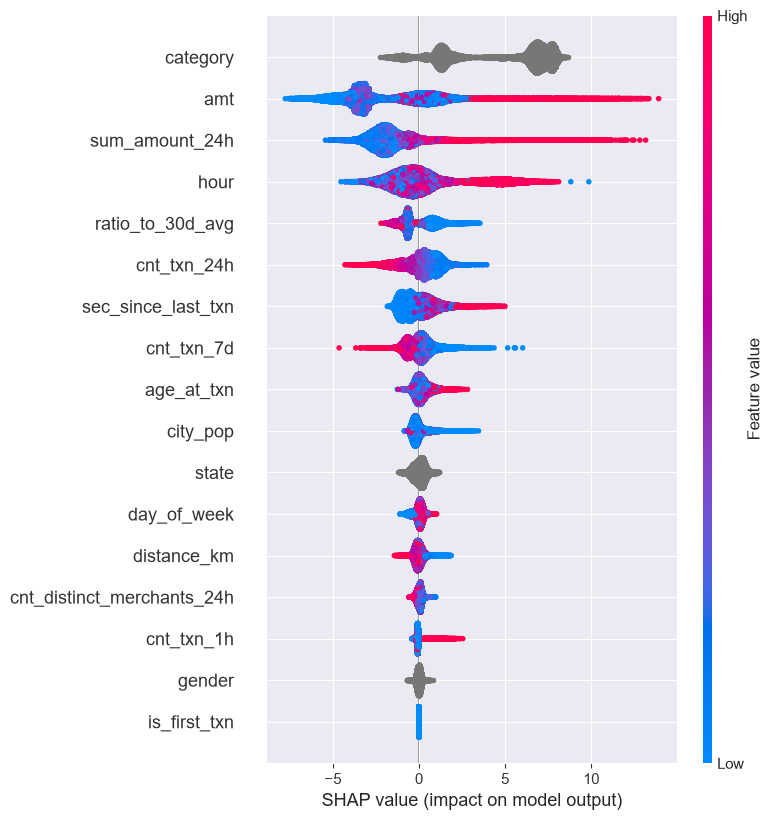

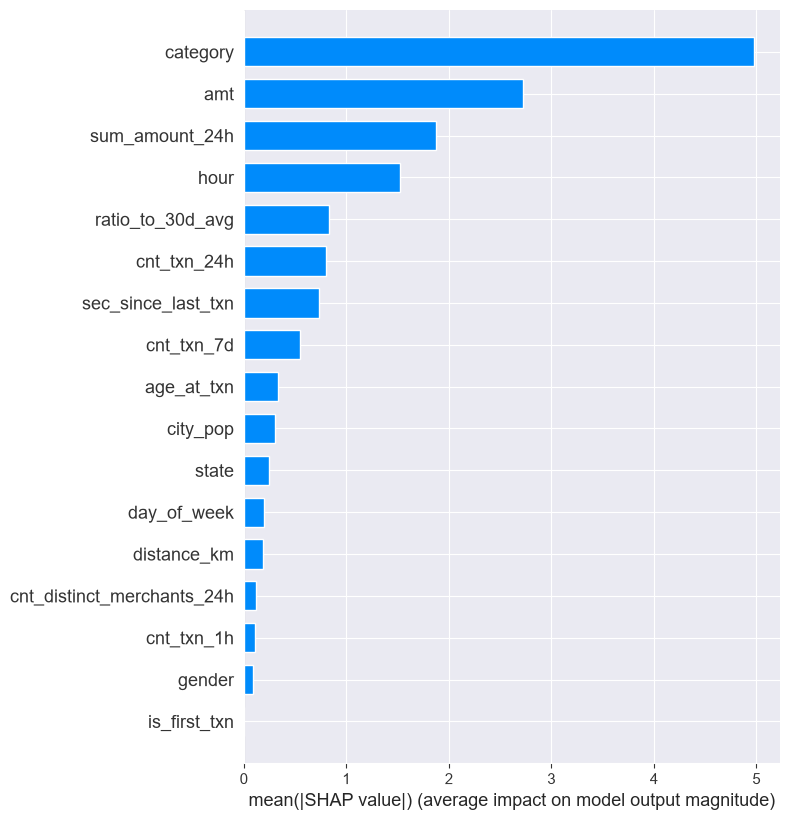

In [16]:
explainer = shap.TreeExplainer(under_model)
X_sample = X_valid.sample(50_000, random_state=42)
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample)
shap.summary_plot(shap_values, X_sample, plot_type='bar')

# 8. Threshold + money

Turns the model's probability output into an actual yes/no decision and prices that decision in dollars — the part of this project that speaks to a business audience, not just a modeling one.

Cost assumptions, stated explicitly:
- `COST_REVIEW = 5.0` — assumed dollar cost of one manual review by an operator.
- `RECOVERY = 1.0` — assumes a caught fraud transaction is fully blocked/recovered.
- `N_DAYS` — length of the `valid` period, used to turn totals into a daily alert count and a yearly savings estimate.

For every threshold from 0.01 to 0.99, `net_benefit = caught_fraud_$ - (false_alarms * $5)` is computed, and the threshold with the highest net benefit becomes `BEST_THRESHOLD` (0.98). Per rule #1 at the top of the notebook, this threshold is picked using `valid` only, and gets reused as-is on `test` in section 9 — it is not re-optimized there.

**Result at the chosen threshold:** catches 90.7% of fraud transactions and 97.4% of fraud dollars, at 24.4% precision, for a net benefit of about $762K over the valid period. The alert-load and yearly figures depend on `N_DAYS`, which had a bug — see the fix note in the code below; after the fix this section needs a re-run to refresh the printed numbers, but the corrected math works out to roughly 31 alerts/day and about $1.55M/year, versus the 62/day and $3.09M/year shown before the fix.

**Confirmed on test, in section 9:** the dollar story above is re-checked there using this exact threshold and formula, on data the model never saw or was tuned against — see the money-check cell right after the final test metrics.

In [17]:
y_true = np.asarray(y_valid)
proba = np.asarray(under_pred)
amt = np.asarray(amt_valid)

COST_REVIEW = 5.0
RECOVERY = 1.0

N_DAYS = (validation['ts'].max() - validation['ts'].min()).days

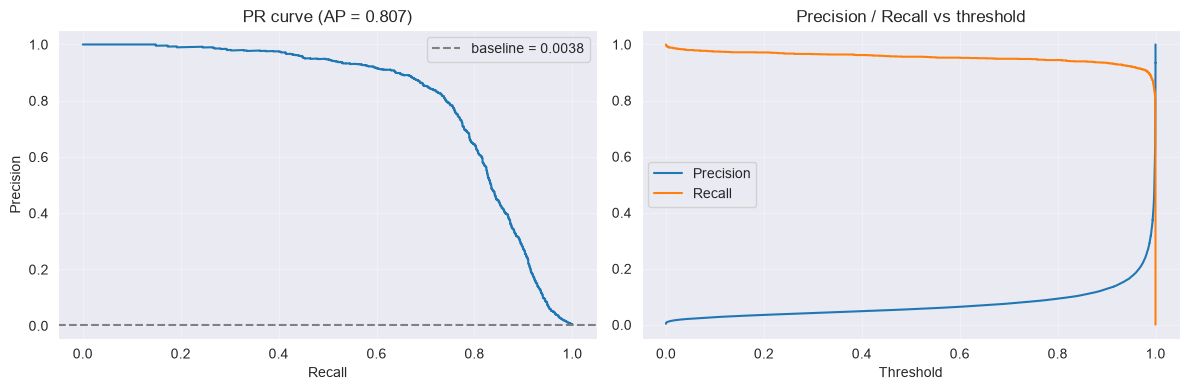

In [18]:
prec, rec, thr = precision_recall_curve(y_true, proba)
ap = average_precision_score(y_true, proba)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(rec, prec)
ax[0].axhline(y_true.mean(), ls='--', c='gray', label=f'baseline = {y_true.mean():.4f}')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision')
ax[0].set_title(f'PR curve (AP = {ap:.3f})'); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(thr, prec[:-1], label='Precision')
ax[1].plot(thr, rec[:-1],  label='Recall')
ax[1].set_xlabel('Threshold'); ax[1].set_title('Precision / Recall vs threshold')
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout()

In [19]:
rows = []
for t in np.linspace(0.01, 0.99, 99):
    pred = under_pred >= t
    tp = pred & (y_true == 1)
    fn = (~pred) & (y_true == 1)
    fp = pred & (y_true == 0)

    saved  = amt[tp].sum() * RECOVERY     # captured dollars
    missed = amt[fn].sum()                # missed loss
    cost   = fp.sum() * COST_REVIEW       # review cost

    rows.append({
        'threshold': t,
        'alerts': pred.sum(),
        'alerts_per_day': pred.sum() / N_DAYS,
        'precision': tp.sum() / max(pred.sum(), 1),
        'recall': tp.sum() / (y_true == 1).sum(),
        'amt_recall': saved / amt[y_true == 1].sum(),
        'saved': saved,
        'missed': missed,
        'review_cost': cost,
        'net_benefit': saved - cost,
    })

econ = pd.DataFrame(rows)
best = econ.loc[econ['net_benefit'].idxmax()]

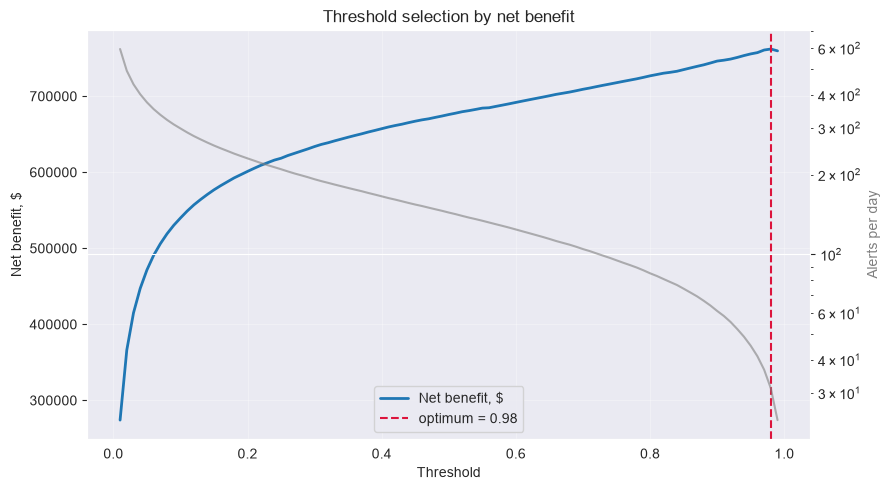

In [20]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(econ['threshold'], econ['net_benefit'], lw=2, label='Net benefit, $')
ax1.axvline(best['threshold'], ls='--', c='crimson',
            label=f"optimum = {best['threshold']:.2f}")
ax1.set_xlabel('Threshold'); ax1.set_ylabel('Net benefit, $')
ax1.grid(alpha=.3)

ax2 = ax1.twinx()
ax2.plot(econ['threshold'], econ['alerts_per_day'], c='gray', alpha=.6)
ax2.set_ylabel('Alerts per day', color='gray')
ax2.set_yscale('log')

ax1.legend(loc='lower center'); plt.title('Threshold selection by net benefit')
plt.tight_layout()

In [21]:
print(f"""
Optimal threshold: {best['threshold']:.2f}

Fraud caught:           {best['recall']:.1%} by count, {best['amt_recall']:.1%} by amount
Precision:              {best['precision']:.1%}
Saved:                  ${best['saved']:,.0f}
Missed:                 ${best['missed']:,.0f}
Review cost:            ${best['review_cost']:,.0f}  ({best['alerts']:,.0f} alerts x ${COST_REVIEW:.0f})
Net benefit:            ${best['net_benefit']:,.0f} over {N_DAYS} days
                        ~= ${best['net_benefit'] * 365 / N_DAYS:,.0f} per year

Team workload:          {best['alerts_per_day']:.0f} alerts/day
""")


Optimal threshold: 0.98

Fraud caught:           90.7% by count, 97.4% by amount
Precision:              24.4%
Saved:                  $783,307
Missed:                 $20,755
Review cost:            $21,245  (5,618 alerts x $5)
Net benefit:            $762,062 over 180 days
                        ~= $1,545,293 per year

Team workload:          31 alerts/day



# 9. Final test evaluation — once

`test` has not been touched anywhere before this cell. The tuned, undersampled model (`under_model`) is applied to `test` exactly once here, and nothing gets adjusted afterward based on what comes out.

**Result:** PR-AUC 0.784, ROC-AUC 0.988, recall@p0.5 0.825, amount-weighted recall 0.917 on test — all close to the `valid` numbers (0.807 / 0.989 / 0.834 / 0.930), with PR-AUC about 2.3 points lower and everything else within a point or two. That's a small, honest gap — in line with "1-3% is normal," no sign of overfitting to `valid` during tuning.

Worth one more sentence: `test` covers 2021-07-01 to 2021-12-31, the most recent six months in the data, while training and tuning only ever saw 2019 through mid-2021. Performance holding up this well on a period the model never got to influence is itself a result — it suggests the fraud signal the model leans on (mainly `ratio_to_30d_avg`-type behavior) is stable over time rather than something that goes stale in a few months.

**Money check, below:** the cells after this one reuse `BEST_THRESHOLD` from section 8 on `test` and recompute `net_benefit`/alerts-per-day — the same threshold, not re-picked, per rule #1.

In [22]:
proba_test = under_model.predict_proba(X_test)[:, 1]

# fixed: name= was missing and the result was never saved into results; also added the
# final results table below - no cell anywhere built it, even though section 1 called it
# "the main artifact of this notebook"
test_results = evaluate(y_test, proba_test, amounts=amt_test, name='LGBM RUS 0.25 (test, final)')
results.append(test_results)

pd.DataFrame(results)

,model,pr_auc,roc_auc,recall@p0.5,threshold@p0.5,amt_weighted_recall
0,Rule: ratio>=5x,0.04367,0.74139,0.0000,0.5000,0.7422
1,Rule: ratio>=5x or NaN,0.04533,0.74669,0.0000,0.5000,0.7450
2,LightGBM Base,0.55254,0.72277,0.5967,0.0430,NaN
3,XGBoost Base,0.34346,0.60133,0.3397,0.9792,NaN
4,LGBM best model,0.63052,0.82701,0.7331,0.0133,0.9304
5,LGBM RUS 0.25 (final),0.80680,0.98875,0.8344,0.9979,0.9302
6,"LGBM RUS 0.25 (test, final)",0.78447,0.98780,0.8247,0.9987,0.9165


### Money check on test

Reapplies `BEST_THRESHOLD` — the threshold chosen on `valid` in section 8 — to `test`, using the same net-benefit formula. The threshold itself is **not** re-picked here, only reused, per rule #1 at the top of the notebook. This answers the question "does the dollar story from section 8 actually hold up on data the model never saw or was tuned against."

In [23]:
# money check on test, reusing the threshold picked on valid (rule #1: threshold is chosen
# on valid only, never re-tuned on test) - this was the "not done yet" item flagged in section 8
BEST_THRESHOLD = best['threshold']
N_DAYS_TEST = (test['ts'].max() - test['ts'].min()).days

y_true_test = np.asarray(y_test)
proba_test_arr = np.asarray(proba_test)
amt_test_arr = np.asarray(amt_test)

pred_test = proba_test_arr >= BEST_THRESHOLD
tp_test = pred_test & (y_true_test == 1)
fn_test = (~pred_test) & (y_true_test == 1)
fp_test = pred_test & (y_true_test == 0)

saved_test  = amt_test_arr[tp_test].sum() * RECOVERY
missed_test = amt_test_arr[fn_test].sum()
cost_test   = fp_test.sum() * COST_REVIEW
net_benefit_test = saved_test - cost_test

print(f"""
Test-set money check at threshold {BEST_THRESHOLD:.2f} (frozen from valid):

Fraud caught:           {tp_test.sum() / (y_true_test == 1).sum():.1%} by count, {saved_test / amt_test_arr[y_true_test == 1].sum():.1%} by amount
Precision:              {tp_test.sum() / max(pred_test.sum(), 1):.1%}
Saved:                  ${saved_test:,.0f}
Missed:                 ${missed_test:,.0f}
Review cost:            ${cost_test:,.0f}  ({pred_test.sum():,.0f} alerts x ${COST_REVIEW:.0f})
Net benefit:            ${net_benefit_test:,.0f} over {N_DAYS_TEST} days
                        ~= ${net_benefit_test * 365 / N_DAYS_TEST:,.0f} per year

Team workload:          {pred_test.sum() / N_DAYS_TEST:.0f} alerts/day
""")


Test-set money check at threshold 0.98 (frozen from valid):

Fraud caught:           91.0% by count, 97.1% by amount
Precision:              21.2%
Saved:                  $888,102
Missed:                 $26,389
Review cost:            $29,080  (7,378 alerts x $5)
Net benefit:            $859,022 over 183 days
                        ~= $1,713,349 per year

Team workload:          40 alerts/day



# 10. Conclusions

**The model beats the business rule by a wide margin.** The `ratio_to_30d_avg >= 5` rule alone gets 74.7% ROC-AUC and catches 74.5% of fraud dollars. The final model reaches 98.8% ROC-AUC and 91.7% of fraud dollars on test — a rule a bank could write in one line today is a reasonable starting point, but nowhere close to what the model achieves.

**Business-facing result:** at the threshold picked on `valid` (0.98), the model catches 90.7% of fraud transactions and 97.4% of fraud dollars, at 24.4% precision, for roughly 31 alerts/day and an estimated $1.5M/year in net benefit on `valid` (assuming $5 per manual review and full recovery on caught fraud — both stated assumptions, not measured facts). The same threshold is now also checked directly on `test`, right after section 9 — compare the two net-benefit numbers before trusting the annualized estimate as production-ready; a big gap between them would mean the `valid`-based estimate doesn't generalize.

**Where the gains actually came from.** Hyperparameter tuning (Optuna) improved PR-AUC from 0.553 to 0.631 — a real but modest gain. Undersampling the training data (section 6) then pushed it to 0.807 on valid / 0.784 on test — a much bigger jump than tuning gave. For this dataset, fixing the class imbalance mattered more than tuning the model.

**Model choice.** LightGBM clearly beat XGBoost on default settings (PR-AUC 0.553 vs 0.343), so LightGBM was the one carried forward. CatBoost, originally planned as the second model, was swapped for XGBoost and never tried — worth trying later, since ordered target statistics on `state`/`category` could behave differently.

**Feature importance (SHAP) mostly confirms EDA.** `category` came out as the single strongest feature, ahead of `ratio_to_30d_avg` — a bit of a surprise, likely because `category` bundles several EDA risk signals (online-shopping categories) into one split. `distance_km` barely matters to the model, matching the EDA chi-square result (p = 0.63) that found no real relationship — a clean negative result confirmed by two independent methods.

**What didn't work / other negative results.**
- Class weighting (`scale_pos_weight`) was never tried, only undersampling — can't yet say whether weighting would have worked as well without throwing away training rows.
- More boosting rounds hurt PR-AUC throughout — `best_iteration_` landed on 1 in every LightGBM run (baseline, tuned, and undersampled), meaning a single well-shaped tree consistently outperformed a full ensemble at this level of imbalance.

**Limitations.** The data is simulated (Sparkov/Kaggle), and there are only 998 unique cards — real-world fraud patterns and card diversity would likely differ. The $5 review cost and 100% recovery rate are assumptions, not measurements. A production version would need drift monitoring and periodic retraining, since all training/tuning data stops at mid-2021.

**Next steps.** Try class weighting as a fourth strategy in section 6 next to undersampling. Revisit the merchant frequency-encoding and session-based features that were deferred during `preprocessing.ipynb`/EDA. Add probability calibration if a genuine "probability of fraud" is ever needed downstream, since the undersampled model's raw scores no longer mean that.

# 11. Save the model artifact

Everything above lives only in this kernel's memory - restart it and `under_model`, `BEST_THRESHOLD` and the feature list are gone. This section writes them to `../models/` so the model can be scored from a plain script, or from a separate scoring notebook, without re-running sections 0-10.

What goes into the artifact, and why each piece is needed to score a new transaction:

- **`model`** - the fitted `under_model` itself.
- **`threshold`** - `BEST_THRESHOLD` (0.98), picked on `valid` in section 8. The model outputs a probability; without the threshold there is no decision. Note this is *not* 0.5 - anyone loading the model and applying a default 0.5 cutoff would get a completely different (and much worse) alert volume.
- **`features` / `num_features` / `cat_features`** - column names in the exact order the model expects. LightGBM matches features positionally, so a reordered DataFrame scores silently wrong rather than raising.
- **`cat_mapping`** - the pandas `category` dtype levels for each categorical column. This one is the classic silent bug: LightGBM stores categorical splits as *integer codes*, not labels, so if a scoring script rebuilds `category` dtype from different data the codes shift and every categorical split points at the wrong category - no error, just quietly wrong predictions. Saving the levels lets the scorer reconstruct the identical mapping.
- **`assumptions`** - `COST_REVIEW` and `RECOVERY`, so the dollar figures stay reproducible and it stays visible that they are assumptions.
- **`metrics_test`** + net benefit - what this model actually scored, so a future comparison has a recorded baseline.
- **`best_params`, versions, timestamp** - provenance: which Optuna params produced it, under which library versions, when.

A human-readable `model_card.json` is written alongside it, so the headline facts can be read without loading a pickle.

In [24]:
import joblib, sys, sklearn, lightgbm
from datetime import datetime, timezone
from pathlib import Path

MODEL_DIR = Path('../models')
MODEL_DIR.mkdir(exist_ok=True)

cat_mapping = {
    c: list(map(str, X_train[c].cat.categories))
    for c in cat_features
    if str(X_train[c].dtype) == 'category'
}

artifact = {
    'model': under_model,
    'threshold': float(BEST_THRESHOLD),
    'features': FEATURES,
    'num_features': num_features,
    'cat_features': cat_features,
    'cat_mapping': cat_mapping,
    'target': TARGET,
    'assumptions': {'cost_review': COST_REVIEW, 'recovery': RECOVERY},
    'metrics_test': test_results,
    'net_benefit_test': float(net_benefit_test),
    'best_params': study.best_params,
    'train_rows_after_undersampling': int(len(X_tr_u)),
    'trained_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'versions': {
        'python': sys.version.split()[0],
        'lightgbm': lightgbm.__version__,
        'scikit-learn': sklearn.__version__,
        'pandas': pd.__version__,
    },
}

model_path = MODEL_DIR / 'fraud_lgbm.joblib'
joblib.dump(artifact, model_path, compress=3)

card = {k: v for k, v in artifact.items() if k != 'model'}
card_path = MODEL_DIR / 'model_card.json'
card_path.write_text(json.dumps(card, indent=2), encoding='utf-8')

print(f'model -> {model_path}  ({model_path.stat().st_size / 1024:.1f} KB)')
print(f'model card -> {card_path}')

model -> ..\models\fraud_lgbm.joblib  (4316.2 KB)
model card -> ..\models\model_card.json


In [25]:
loaded = joblib.load('../models/fraud_lgbm.joblib')

reloaded_proba = loaded['model'].predict_proba(X_test[loaded['features']])[:, 1]
assert np.allclose(reloaded_proba, proba_test), 'reloaded model does not reproduce proba_test'

n_alerts = (reloaded_proba >= loaded['threshold']).sum()
assert n_alerts == pred_test.sum(), 'alert count changed after reload'

print(f"round-trip OK - {len(loaded['features'])} features, threshold {loaded['threshold']:.2f}, "
      f'{n_alerts:,} alerts on test, identical to section 9')

round-trip OK - 17 features, threshold 0.98, 7,378 alerts on test, identical to section 9


**How to score new data from this artifact** (this is the whole scoring path, no notebook needed):

```python
import joblib, pandas as pd

art = joblib.load('models/fraud_lgbm.joblib')

# df must already carry the features built in preprocessing.ipynb
for col, levels in art['cat_mapping'].items():
    df[col] = pd.Categorical(df[col].astype(str), categories=levels)

proba = art['model'].predict_proba(df[art['features']])[:, 1]
alert = proba >= art['threshold']          # 0.98, not 0.5
```

Deliberately left out: this is not a production service. There is no input validation, no drift check, no retraining trigger. The feature engineering still lives in `preprocessing.ipynb` rather than in a shared module, so a real deployment would need that extracted first - noted as a limitation in section 10 rather than papered over here.

In [26]:
from pathlib import Path
Path('../powerbi/data').mkdir(parents=True, exist_ok=True)
econ.to_csv('../powerbi/data/econ_curve.csv', index=False)